# Baseline de classification avec Scikit-Learn

## Contexte

Après la phase d'exploration et de préparation des données, une première référence de performance doit être établie avant l'utilisation de modèles de Deep Learning.

Cette baseline permettra de :

- fournir un point de comparaison pour les futurs modèles ;
- évaluer la difficulté réelle du problème ;
- analyser les capacités d'un algorithme classique de Machine Learning sur le dataset MNIST.

## Objectif

Construire une baseline reproductible à l'aide d'une régression logistique et évaluer ses performances de manière rigoureuse.

## Questions étudiées

Cette expérimentation cherche notamment à répondre aux questions suivantes :

1. Quelle performance peut être obtenue avec un modèle classique de Machine Learning ?
2. Quel coefficient de régularisation est le plus adapté aux données ?
3. Quelle est la stabilité des performances observées lors de la validation croisée ?
4. Quelle est la performance réelle du modèle sur un jeu de validation indépendant ?
5. Quelles améliorations pourront être apportées par les futurs modèles MLP et CNN ?

## Résultats attendus

Les résultats obtenus serviront de référence pour l'ensemble des expérimentations ultérieures du projet.

---

# Protocole expérimental

## Jeux de données

Conformément au protocole défini lors de la phase d'exploration :

| Ensemble | Taille | Utilisation |
|-----------|-----------:|-----------|
| Entraînement | 54 000 | Apprentissage des modèles |
| Validation | 6 000 | Évaluation des performances |
| Test | 10 000 | Évaluation finale uniquement |

## Validation croisée

Le coefficient de régularisation de la régression logistique sera sélectionné automatiquement à l'aide d'une validation croisée à 10 folds réalisée uniquement sur l'ensemble d'entraînement.

Cette validation croisée permettra de mesurer :

- la performance moyenne du modèle ;
- sa stabilité ;
- l'incertitude associée aux performances observées.

Les indicateurs suivants seront calculés :

- Accuracy moyenne ;
- Écart-type ;
- Intervalle de confiance à 95 %.

## Évaluation finale

Une fois le meilleur modèle sélectionné :

- l'entraînement est réalisé sur l'ensemble d'entraînement ;
- l'évaluation est réalisée sur l'ensemble de validation.

Les métriques suivantes seront calculées :

- Accuracy ;
- Precision macro ;
- Recall macro ;
- F1-score macro.

## Prévention de la fuite de données

Le jeu de test n'est utilisé à aucun moment durant cette expérimentation.

Toutes les décisions de conception sont prises uniquement à partir des ensembles d'entraînement et de validation.

Le jeu de test est réservé à l'évaluation finale du projet conformément aux consignes du sujet.

---

# Chargement des bibliothèques

In [ ]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

# Reproductibilité

Afin de garantir la reproductibilité des expériences, une graine aléatoire fixe est utilisée.

In [29]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print(f"Seed fixée : {SEED}")

Seed fixée : 42


# Chargement des données préparées

Les ensembles d'entraînement et de validation créés lors de la phase d'exploration sont chargés depuis le dossier `data/processed`.

Le jeu de test n'est pas chargé dans ce notebook afin de respecter le protocole expérimental défini précédemment.

Les données utilisées sont donc exclusivement :

- l'ensemble d'entraînement (54 000 images) ;
- l'ensemble de validation (6 000 images).

In [30]:
x_train = np.load("../data/processed/x_train.npy")

y_train = np.load("../data/processed/y_train.npy")

x_val = np.load("../data/processed/x_val.npy")

y_val = np.load("../data/processed/y_val.npy")

# Vérification des données chargées

Avant toute expérimentation, il est nécessaire de vérifier que les ensembles chargés correspondent aux dimensions attendues.

Les vérifications portent sur :

- le nombre d'images ;
- le nombre de labels ;
- les dimensions des images ;
- la cohérence entre les ensembles d'entraînement et de validation.

## Vérification des dimensions 

In [31]:
print("Ensemble d'entraînement")
print(f"x_train : {x_train.shape}")
print(f"y_train : {y_train.shape}")

print("\nEnsemble de validation")
print(f"x_val : {x_val.shape}")
print(f"y_val : {y_val.shape}")

Ensemble d'entraînement
x_train : (54000, 28, 28)
y_train : (54000,)

Ensemble de validation
x_val : (6000, 28, 28)
y_val : (6000,)


## Vérification de la cohérence labels/images

In [32]:
assert len(x_train) == len(y_train)
assert len(x_val) == len(y_val)

print("Correspondance images / labels validée ✅")

Correspondance images / labels validée ✅


## Vérificaiton des dimensions des images 

In [33]:
print(f"Dimensions d'une image : {x_train[0].shape}")

Dimensions d'une image : (28, 28)


## Vérification des valeurs

In [34]:
print(f"Valeur minimale : {x_train.min():.4f}")

print(f"Valeur maximale : {x_train.max():.4f}")

Valeur minimale : 0.0000
Valeur maximale : 1.0000


## Tableau récapitulatif

In [35]:
datasets_df = pd.DataFrame(
    {
        "Ensemble": [
            "Train",
            "Validation",
        ],
        "Images": [
            len(x_train),
            len(x_val),
        ],
        "Labels": [
            len(y_train),
            len(y_val),
        ],
    }
)

datasets_df

,Ensemble,Images,Labels
0,Train,54000,54000
1,Validation,6000,6000


# Analyse

Les vérifications confirment que les ensembles chargés correspondent aux données préparées lors de la phase d'exploration.

Les dimensions observées sont conformes au protocole expérimental :

- 54 000 images pour l'entraînement ;
- 6 000 images pour la validation ;
- dimensions des images : 28 × 28 pixels.

Les valeurs des pixels sont comprises entre 0 et 1, ce qui confirme que la normalisation réalisée précédemment a été correctement conservée.

Les données sont donc prêtes pour l'entraînement d'un modèle de classification.

# Conclusion intermédiaire

Les données ont été chargées et vérifiées avec succès.

La prochaine étape consiste à sélectionner le modèle de référence puis à préparer les images pour leur utilisation avec Scikit-Learn.

---

# Choix du modèle de référence

Plusieurs algorithmes classiques de Machine Learning peuvent être utilisés comme baseline sur le dataset MNIST.

Deux candidats principaux ont été envisagés :

- la régression logistique ;
- la forêt aléatoire.

## Régression logistique

La régression logistique constitue une référence classique pour les problèmes de classification multiclasse.

Ses principaux avantages sont :

- simplicité d'utilisation ;
- rapidité d'entraînement ;
- faible nombre d'hyperparamètres ;
- bonne interprétabilité ;
- performances généralement compétitives sur MNIST.

## Forêt aléatoire

Les forêts aléatoires permettent de modéliser des relations non linéaires entre les variables et peuvent atteindre de bonnes performances sur certains problèmes de classification.

Cependant :

- leur temps d'entraînement est plus élevé ;
- elles nécessitent davantage de réglages ;
- elles sont moins couramment utilisées comme baseline de référence sur MNIST.

## Choix retenu

Nous retenons donc la régression logistique.

Afin d'éviter un réglage manuel du coefficient de régularisation, nous utilisons la classe `LogisticRegressionCV` de Scikit-Learn.

Cette méthode sélectionne automatiquement le meilleur coefficient de régularisation à l'aide d'une validation croisée réalisée uniquement sur l'ensemble d'entraînement.

---

# Préparation des données

Les algorithmes de Scikit-Learn attendent des données tabulaires sous la forme :

```text
(n_samples, n_features)
```

Les images MNIST étant représentées sous la forme de matrices 28 × 28, elles doivent être transformées en vecteurs de 784 caractéristiques avant l'entraînement du modèle.

In [36]:
x_train_flat = x_train.reshape(
    x_train.shape[0],
    -1,
)

x_val_flat = x_val.reshape(
    x_val.shape[0],
    -1,
)

print("Train :", x_train_flat.shape)
print("Validation :", x_val_flat.shape)

Train : (54000, 784)
Validation : (6000, 784)


In [37]:
print(f"Nombre de caractéristiques : {x_train_flat.shape[1]}")

Nombre de caractéristiques : 784


# Analyse

La transformation des images a été réalisée avec succès.

Chaque image de taille 28 × 28 pixels est désormais représentée par un vecteur de 784 caractéristiques.

Cette représentation est compatible avec les modèles classiques de Machine Learning proposés par Scikit-Learn.

Contrairement aux futurs CNN, la régression logistique ne tient pas compte explicitement de l'organisation spatiale des pixels et considère chaque pixel comme une caractéristique indépendante.

---
# Paramétrage du modèle


# Validation croisée

Le coefficient de régularisation de la régression logistique est sélectionné automatiquement à l'aide d'une validation croisée à 10 folds.

## Pourquoi 10 folds ?

Les valeurs les plus fréquemment rencontrées dans la littérature sont :

- 3 folds ;
- 5 folds ;
- 10 folds.

Le dataset MNIST contenant un grand nombre d'observations, nous retenons une validation croisée à 10 folds.

Ce choix permet :

- une estimation plus robuste des performances ;
- une meilleure utilisation des données ;
- une mesure plus fiable de la variabilité des résultats.

La validation croisée est réalisée uniquement sur l'ensemble d'entraînement.

L'ensemble de validation reste indépendant et n'intervient à aucun moment dans le choix des hyperparamètres.

# Paramétrage de la régression logistique

La classe `LogisticRegressionCV` est utilisée afin de sélectionner automatiquement le meilleur coefficient de régularisation.

Le solveur LBFGS est retenu car il est adapté aux problèmes de classification multiclasse.

Les principaux paramètres retenus sont :

- `cv=10`
- `solver="lbfgs"`
- `random_state=42`
- `max_iter=1000`
- `n_jobs=-1`

In [38]:
baseline_model = LogisticRegressionCV(
    cv=10,
    solver="lbfgs",
    random_state=SEED,
    max_iter=1000,
    n_jobs=-1,
)

# Entraînement du modèle

Le modèle est entraîné sur l'ensemble d'entraînement composé de 54 000 images.

Le temps d'entraînement est mesuré afin de documenter le coût computationnel de cette baseline.

In [39]:
start_time = time.time()

baseline_model.fit(
    x_train_flat,
    y_train,
)

training_time = time.time() - start_time

/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressio

In [40]:
print(f"Temps d'entraînement : {training_time:.2f} secondes")

print(f"Meilleur C : {baseline_model.C_[0]:.6f}")

Temps d'entraînement : 240.88 secondes
Meilleur C : 0.359381


# Résultats bruts de la validation croisée

Les scores obtenus durant les 10 folds sont exploités afin d'étudier le comportement du modèle selon les différentes valeurs du coefficient de régularisation.

Pour chaque valeur de C, nous calculons :

- l'accuracy moyenne ;
- l'écart-type ;
- l'intervalle de confiance à 95 %.

In [ ]:
mean_scores = np.mean(
    baseline_model.scores_[0],
    axis=0,
)

std_scores = np.std(
    baseline_model.scores_[0],
    axis=0,
    ddof=1,
)

cv_results = pd.DataFrame(
    {
        "C": baseline_model.Cs_,
        "Accuracy moyenne": mean_scores,
        "Écart-type": std_scores,
    }
)

cv_results

,C,Accuracy moyenne,Écart-type
0,0.000100,0.842556,0.004618
1,0.000774,0.885630,0.004497
2,0.005995,0.908611,0.003221
3,0.046416,0.919833,0.002865
4,0.359381,0.921407,0.002642
5,2.782559,0.917593,0.003698
6,21.544347,0.917593,0.003698
7,166.810054,0.917593,0.003698
8,1291.549665,0.917593,0.003698
9,10000.000000,0.917593,0.003698


# Calcul des intervalles de confiance

In [42]:
n_folds = 10

confidence_intervals = []

for i in range(len(mean_scores)):
    ci_low, ci_high = stats.t.interval(
        confidence=0.95,
        df=n_folds - 1,
        loc=mean_scores[i],
        scale=std_scores[i] / np.sqrt(n_folds),
    )

    confidence_intervals.append((ci_low, ci_high))

cv_results["IC95 bas"] = [ci[0] for ci in confidence_intervals]

cv_results["IC95 haut"] = [ci[1] for ci in confidence_intervals]

cv_results

,C,Accuracy moyenne,Écart-type,IC95 bas,IC95 haut
0,0.000100,0.842556,0.004618,0.839252,0.845859
1,0.000774,0.885630,0.004497,0.882413,0.888846
2,0.005995,0.908611,0.003221,0.906307,0.910915
3,0.046416,0.919833,0.002865,0.917783,0.921883
4,0.359381,0.921407,0.002642,0.919517,0.923298
5,2.782559,0.917593,0.003698,0.914948,0.920238
6,21.544347,0.917593,0.003698,0.914948,0.920238
7,166.810054,0.917593,0.003698,0.914948,0.920238
8,1291.549665,0.917593,0.003698,0.914948,0.920238
9,10000.000000,0.917593,0.003698,0.914948,0.920238


# Sauvegarde des résultats CV

In [43]:
cv_results.to_csv(
    "../reports/experiments/baseline_model_cv_results.csv",
    index=False,
)

# Graphique de validaiton croisée

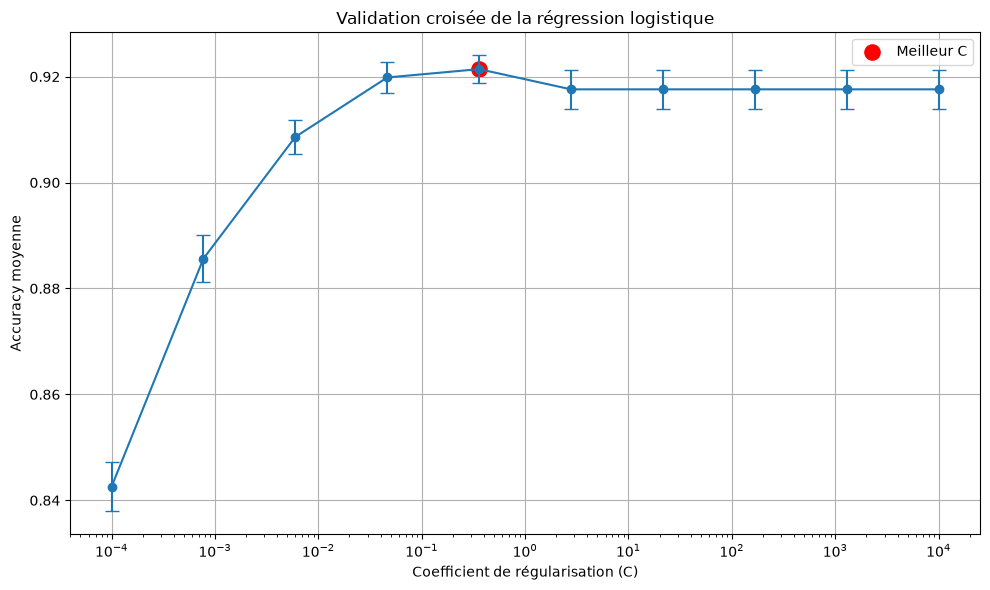

In [44]:
best_idx = np.argmax(mean_scores)

plt.figure(figsize=(10, 6))

plt.errorbar(
    baseline_model.Cs_,
    mean_scores,
    yerr=std_scores,
    fmt="o-",
    capsize=5,
)

plt.scatter(
    baseline_model.Cs_[best_idx],
    mean_scores[best_idx],
    color="red",
    s=120,
    label="Meilleur C",
)

plt.xscale("log")

plt.title("Validation croisée de la régression logistique")

plt.xlabel("Coefficient de régularisation (C)")

plt.ylabel("Accuracy moyenne")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_cross_validation.png",
    bbox_inches="tight",
)

plt.show()

# Analyse statistique de la validation croisée

La validation croisée à 10 folds a permis d'évaluer l'influence du coefficient de régularisation sur les performances du modèle.

Les résultats montrent que :

- une régularisation trop forte (faibles valeurs de C) entraîne une baisse importante des performances ;
- les performances augmentent progressivement lorsque la régularisation diminue ;
- un optimum est atteint pour :

```text
C = 0.359381
```

avec :

```text
Accuracy moyenne = 92.14 %
Écart-type = 0.26 %
```

L'intervalle de confiance à 95 % associé est :

```text
[91.95 % ; 92.33 %]
```

La faible valeur de l'écart-type indique que les performances observées varient peu d'un fold à l'autre.

Le modèle apparaît donc robuste vis-à-vis du découpage des données utilisé pour la validation croisée.

Au-delà de la valeur optimale de C, les performances diminuent légèrement puis se stabilisent, ce qui suggère qu'une diminution supplémentaire de la régularisation n'apporte aucun bénéfice significatif.

Ces résultats justifient le choix automatique du coefficient de régularisation réalisé par LogisticRegressionCV.

# Modèle final retenu

À l'issue de la validation croisée, le coefficient de régularisation optimal est sélectionné automatiquement.

Le modèle correspondant sera utilisé pour l'évaluation finale sur l'ensemble de validation indépendant.

Conformément au protocole expérimental, cet ensemble de validation n'a jamais été utilisé au cours de la validation croisée.

In [45]:
best_idx = np.argmax(mean_scores)

best_c = baseline_model.Cs_[best_idx]

print(f"C optimal : {best_c:.6f}")

mean_accuracy = mean_scores[best_idx]
std_accuracy = std_scores[best_idx]

print(f"Accuracy CV : {mean_accuracy:.4%}")

print(f"Écart-type CV : {std_accuracy:.4%}")

C optimal : 0.359381
Accuracy CV : 92.1407%
Écart-type CV : 0.2642%


In [46]:
cv_summary = pd.DataFrame(
    {
        "C optimal": [best_c],
        "Accuracy CV": [mean_accuracy],
        "Écart-type CV": [std_accuracy],
    }
)

cv_summary

,C optimal,Accuracy CV,Écart-type CV
0,0.359381,0.921407,0.002642


In [47]:
cv_summary.to_csv(
    "../reports/experiments/baseline_cv_summary.csv",
    index=False,
)

---

# Évaluation sur l'ensemble de validation

La validation croisée a permis de sélectionner automatiquement le coefficient de régularisation optimal.

Nous évaluons maintenant le modèle final sur l'ensemble de validation indépendant.

Cet ensemble n'a jamais été utilisé pour :

- l'entraînement ;
- la sélection du coefficient de régularisation ;
- le choix du modèle.

Les performances observées constituent donc une estimation indépendante de la capacité de généralisation de la baseline.

# Prédictions

In [48]:
y_val_pred = baseline_model.predict(x_val_flat)

In [53]:
print(f"Nombre de prédictions : {len(y_val_pred)} / {len(y_val)}")

Nombre de prédictions : 6000 / 6000


# Métriques d'évaluation

Plusieurs métriques complémentaires sont utilisées.

## Accuracy

Proportion globale de prédictions correctes.

## Precision macro

Moyenne de la précision calculée indépendamment pour chacune des classes.

## Recall macro

Moyenne du rappel calculé indépendamment pour chacune des classes.

## F1-score macro

Moyenne harmonique entre précision et rappel.

Les versions macro sont retenues afin d'accorder le même poids à chacune des dix classes du problème.

In [54]:
accuracy = accuracy_score(
    y_val,
    y_val_pred,
)

precision = precision_score(
    y_val,
    y_val_pred,
    average="macro",
)

recall = recall_score(
    y_val,
    y_val_pred,
    average="macro",
)

f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro",
)

In [56]:
results_df = pd.DataFrame(
    {
        "Métrique": [
            "Accuracy",
            "Precision macro",
            "Recall macro",
            "F1-score macro",
        ],
        "Valeur": [
            accuracy,
            precision,
            recall,
            f1,
        ],
    }
)

results_df
results_df.to_csv(
    "../reports/experiments/baseline_metrics.csv",
    index=False,
)

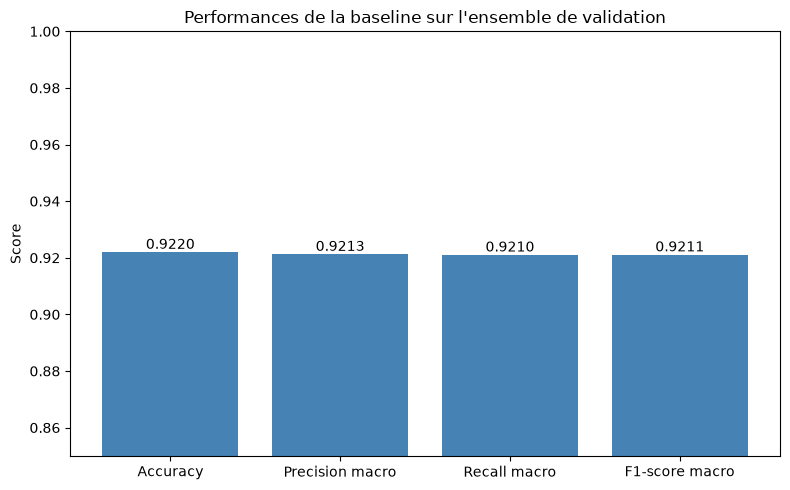

In [57]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df["Métrique"],
    results_df["Valeur"],
    color="steelblue",
)

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom",
    )

plt.ylim(0.85, 1.0)

plt.title("Performances de la baseline sur l'ensemble de validation")

plt.ylabel("Score")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_metrics.png",
    bbox_inches="tight",
)

plt.show()

# Estimation de l'incertitude sur l'ensemble de validation

L'ensemble de validation ne fournit qu'une mesure ponctuelle des performances.

Afin d'estimer l'incertitude associée à cette mesure, un bootstrap est réalisé.

Le bootstrap consiste à rééchantillonner plusieurs fois l'ensemble de validation avec remise afin d'obtenir une distribution empirique de l'accuracy.

In [58]:
n_bootstrap = 1000

bootstrap_scores = []

for _ in range(n_bootstrap):
    indices = np.random.choice(
        len(y_val),
        size=len(y_val),
        replace=True,
    )

    score = accuracy_score(
        y_val[indices],
        y_val_pred[indices],
    )

    bootstrap_scores.append(score)

bootstrap_scores = np.array(bootstrap_scores)

In [59]:
bootstrap_mean = bootstrap_scores.mean()

bootstrap_std = bootstrap_scores.std(ddof=1)

ci_low = np.percentile(
    bootstrap_scores,
    2.5,
)

ci_high = np.percentile(
    bootstrap_scores,
    97.5,
)

print(f"Accuracy bootstrap : {bootstrap_mean:.4%}")

print(f"Écart-type bootstrap : {bootstrap_std:.4%}")

print(f"IC95 % : [{ci_low:.4%} ; {ci_high:.4%}]")

Accuracy bootstrap : 92.1793%
Écart-type bootstrap : 0.3412%
IC95 % : [91.5000% ; 92.8342%]


In [61]:
bootstrap_summary = pd.DataFrame(
    {
        "Metric": ["Accuracy"],
        "Mean": [bootstrap_mean],
        "Std": [bootstrap_std],
        "CI95_low": [ci_low],
        "CI95_high": [ci_high],
    }
)

bootstrap_summary
bootstrap_summary.to_csv(
    "../reports/experiments/baseline_bootstrap_results.csv",
    index=False,
)

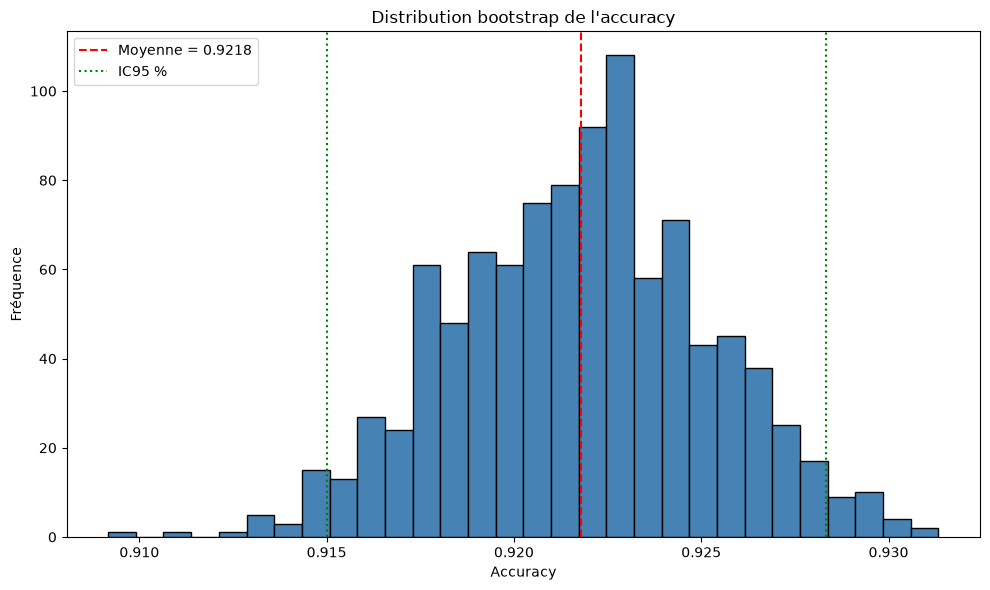

In [62]:
plt.figure(figsize=(10, 6))

plt.hist(
    bootstrap_scores,
    bins=30,
    color="steelblue",
    edgecolor="black",
)

plt.axvline(
    bootstrap_mean,
    color="red",
    linestyle="--",
    label=f"Moyenne = {bootstrap_mean:.4f}",
)

plt.axvline(ci_low, color="green", linestyle=":", label="IC95 %")

plt.axvline(ci_high, color="green", linestyle=":")

plt.title("Distribution bootstrap de l'accuracy")

plt.xlabel("Accuracy")
plt.ylabel("Fréquence")

plt.legend()

plt.tight_layout()

plt.savefig("../reports/figures/baseline_bootstrap_accuracy.png", bbox_inches="tight")

plt.show()

# Analyse de l'incertitude sur l'ensemble de validation

Un bootstrap à 1000 rééchantillonnages a été réalisé afin d'estimer l'incertitude associée aux performances observées sur l'ensemble de validation.

Les résultats obtenus sont :

- Accuracy moyenne : 92,18 % ;
- Écart-type : 0,34 % ;
- IC95 % : [91,50 % ; 92,83 %].

L'accuracy observée sur l'ensemble de validation (92,20 %) se situe au centre de cet intervalle.

Ces résultats renforcent la confiance dans la stabilité des performances du modèle et suggèrent que les résultats obtenus ne dépendent pas fortement d'un sous-échantillonnage particulier des données.

# Analyse globale des résultats

L'expérimentation réalisée permet d'évaluer la capacité d'une régression logistique à résoudre le problème de classification des chiffres manuscrits MNIST.

La validation croisée à 10 folds a mis en évidence un coefficient de régularisation optimal :

C = 0.359381

Pour cette valeur, les performances moyennes observées sont :

- Accuracy moyenne : 92,14 %
- Écart-type : 0,26 %
- IC95 % : [91,95 % ; 92,33 %]

La faible dispersion observée entre les folds indique une bonne stabilité du modèle vis-à-vis du découpage des données d'entraînement.

L'évaluation réalisée sur l'ensemble de validation indépendant confirme ces observations :

- Accuracy : 92,20 %
- Precision macro : 92,13 %
- Recall macro : 92,10 %
- F1-score macro : 92,11 %

Les différentes métriques présentent des valeurs très proches, ce qui est cohérent avec l'équilibre des classes observé lors de l'analyse exploratoire.

L'écart extrêmement faible entre l'accuracy moyenne obtenue durant la validation croisée et l'accuracy mesurée sur l'ensemble de validation suggère une bonne capacité de généralisation du modèle et l'absence de surapprentissage significatif.

# Analyse de l'incertitude et de la robustesse

Afin d'estimer l'incertitude associée aux performances observées sur l'ensemble de validation, un bootstrap à 1 000 rééchantillonnages a été réalisé.

Les résultats obtenus sont :

- Accuracy moyenne bootstrap : 92,18 %
- Écart-type bootstrap : 0,34 %
- IC95 % : [91,50 % ; 92,83 %]

L'accuracy observée sur l'ensemble de validation (92,20 %) se situe au centre de cet intervalle de confiance.

Cette cohérence entre :

- validation croisée ;
- validation indépendante ;
- bootstrap ;

renforce la confiance dans les performances observées.

Les résultats obtenus apparaissent donc robustes et peu sensibles aux fluctuations dues au découpage des données.


# Limites de la baseline

Malgré des performances satisfaisantes, la régression logistique présente plusieurs limitations.

Chaque pixel est traité comme une caractéristique indépendante, sans prise en compte explicite de la structure spatiale des images.

Le modèle ne peut donc pas exploiter efficacement :

- les motifs locaux ;
- les formes géométriques ;
- les relations entre pixels voisins.

Cette limitation explique vraisemblablement pourquoi les performances plafonnent autour de 92 %.

Les futurs modèles de Deep Learning, notamment les réseaux de neurones convolutifs, devraient être capables de mieux exploiter la structure des images et d'améliorer significativement les performances obtenues.

# Conclusion BASELINE-01

Une baseline reproductible fondée sur une régression logistique avec validation croisée a été construite avec succès.

La validation croisée à 10 folds a permis de sélectionner automatiquement un coefficient de régularisation optimal :

C = 0.359381

Les performances observées sont :

- Accuracy moyenne CV : 92,14 % ± 0,26 %
- IC95 % CV : [91,95 % ; 92,33 %]

L'évaluation sur l'ensemble de validation indépendant donne :

- Accuracy : 92,20 %
- Precision macro : 92,13 %
- Recall macro : 92,10 %
- F1-score macro : 92,11 %

Le bootstrap confirme la stabilité de ces résultats avec un intervalle de confiance à 95 % de :

[91,50 % ; 92,83 %]

Cette baseline fournit désormais une référence solide pour l'ensemble du projet.

Les prochaines étapes consisteront à :

- analyser les erreurs du modèle ;
- étudier sa matrice de confusion ;
- identifier les chiffres les plus difficiles à reconnaître ;

avant de comparer ces résultats aux futurs modèles MLP puis CNN.

---
# Matrice de confusion

Les métriques globales précédemment calculées fournissent une vision synthétique des performances du modèle.

Cependant, elles ne permettent pas d'identifier précisément quelles classes sont correctement reconnues et quelles classes sont confondues.

La matrice de confusion permet d'étudier le comportement du classifieur pour chaque chiffre individuellement.

Deux représentations seront étudiées :

- une matrice brute indiquant le nombre d'images classées dans chaque catégorie ;
- une matrice normalisée indiquant les proportions de classification.

Cette analyse permettra d'identifier les chiffres les plus difficiles à distinguer et de préparer l'étude détaillée des erreurs de classification.

# Calcul des matrices

In [64]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    y_val_pred,
)

cm_normalized = confusion_matrix(
    y_val,
    y_val_pred,
    normalize="true",
)
cm_df = pd.DataFrame(
    cm,
    index=range(10),
    columns=range(10),
)

cm_df.to_csv("../reports/experiments/baseline_confusion_matrix.csv")

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=range(10),
    columns=range(10),
)

cm_normalized_df.to_csv(
    "../reports/experiments/baseline_confusion_matrix_normalized.csv"
)

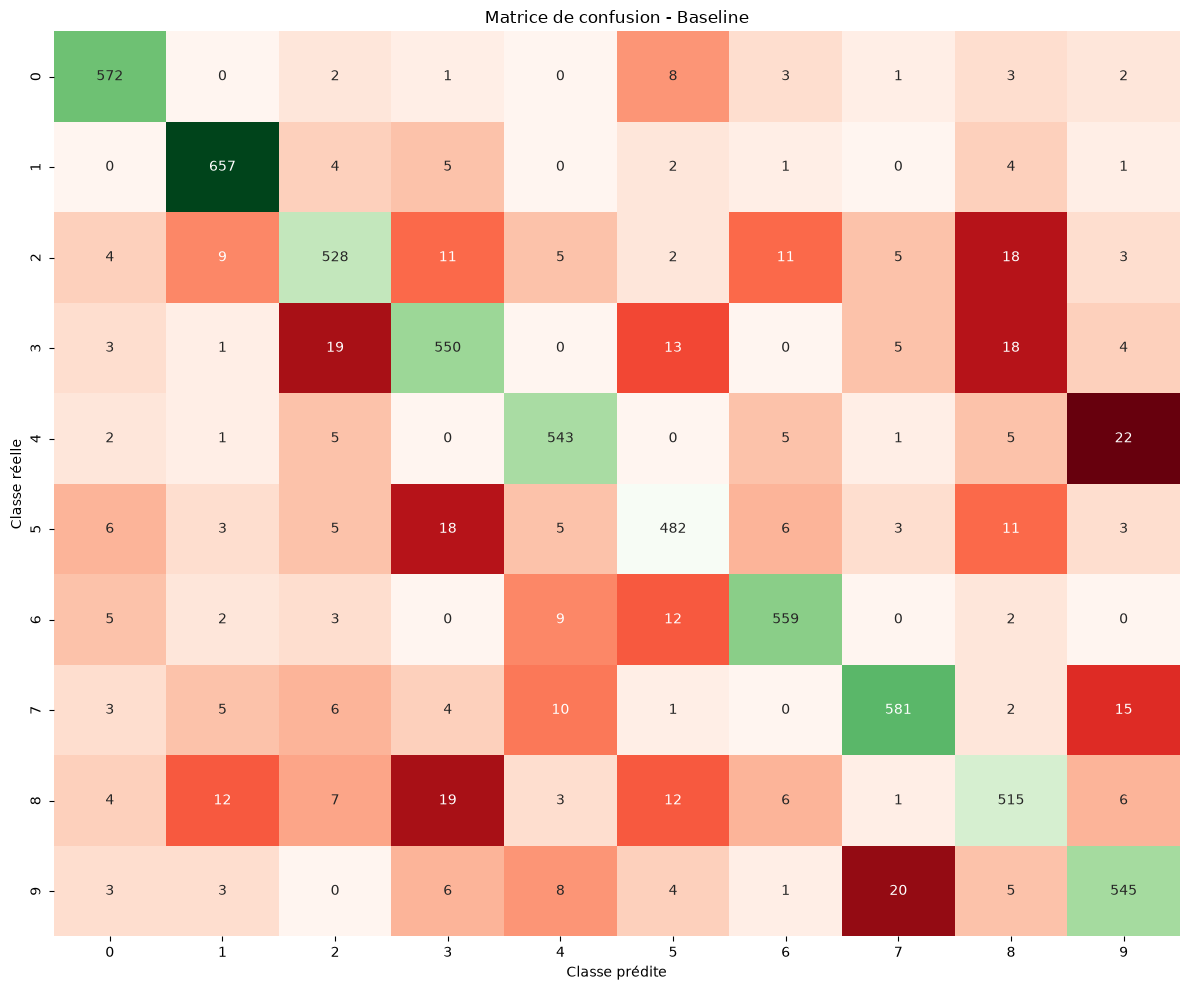

In [72]:
plt.figure(figsize=(12, 10))

mask_diag = np.eye(cm.shape[0], dtype=bool)

# Erreurs
sns.heatmap(
    cm,
    mask=mask_diag,
    annot=True,
    fmt="d",
    cmap="Reds",
    cbar=False,
)

# Succès
sns.heatmap(
    cm,
    mask=~mask_diag,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
)

plt.title("Matrice de confusion - Baseline")

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_confusion_matrix.png",
    bbox_inches="tight",
)

plt.show()

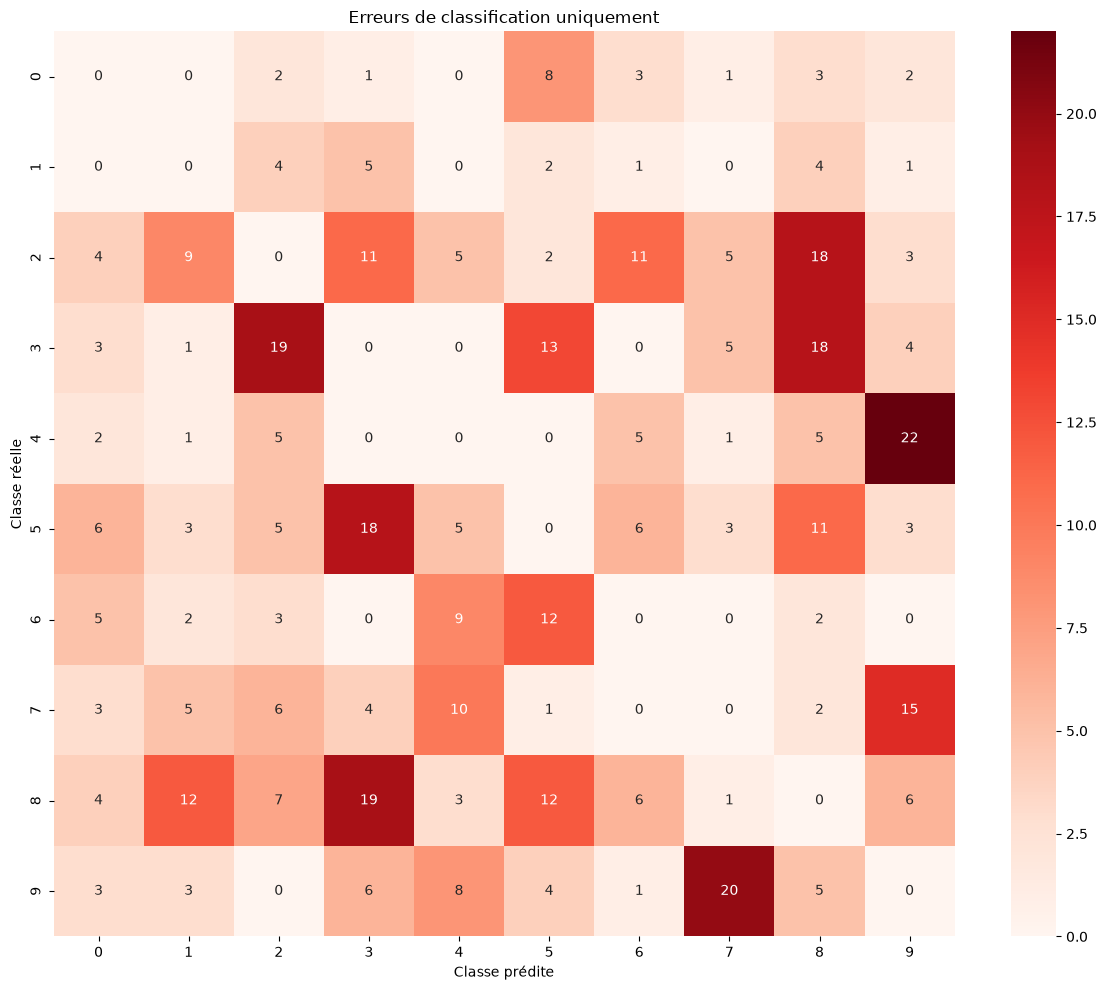

In [73]:
error_matrix = cm.copy()

np.fill_diagonal(error_matrix, 0)
plt.figure(figsize=(12, 10))

sns.heatmap(error_matrix, annot=True, fmt="d", cmap="Reds")

plt.title("Erreurs de classification uniquement")

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_confusion_errors.png",
    bbox_inches="tight",
)

plt.show()

# Analyse de la matrice de confusion brute

La matrice de confusion brute présente le nombre d'exemples attribués à chaque classe.

Les valeurs situées sur la diagonale correspondent aux classifications correctes tandis que les valeurs hors diagonale représentent les erreurs de classification.

## Observations générales

La diagonale principale domine largement la matrice, ce qui confirme les bonnes performances globales observées précédemment lors de l'évaluation du modèle.

Les plus grands nombres se situent systématiquement sur la diagonale, indiquant qu'une majorité d'images est correctement reconnue pour chacune des dix classes.

## Classes les mieux reconnues

Les chiffres présentant le plus grand nombre de classifications correctes sont notamment :

- Classe 1 : 657 classifications correctes ;
- Classe 7 : 581 classifications correctes ;
- Classe 0 : 572 classifications correctes ;
- Classe 6 : 559 classifications correctes ;
- Classe 3 : 550 classifications correctes ;
- Classe 9 : 545 classifications correctes.

Ces résultats suggèrent que ces chiffres possèdent des caractéristiques visuelles relativement faciles à distinguer pour la régression logistique.

## Principales confusions observées

Plusieurs erreurs apparaissent de manière récurrente :

- 4 → 9 : 22 erreurs ;
- 9 → 7 : 20 erreurs ;
- 3 → 2 : 19 erreurs ;
- 8 → 3 : 19 erreurs ;
- 5 → 3 : 18 erreurs ;
- 2 → 8 : 18 erreurs.

Ces confusions concernent principalement des chiffres présentant des formes manuscrites proches ou pouvant partager certaines caractéristiques géométriques.

## Interprétation

La matrice brute montre que la majorité des erreurs se concentre sur un nombre limité de couples de classes.

Les difficultés rencontrées semblent moins liées à un manque de données qu'à la capacité limitée de la régression logistique à modéliser certaines structures visuelles complexes présentes dans les chiffres manuscrits.

Cette observation justifie l'utilisation ultérieure de modèles plus sophistiqués capables d'exploiter davantage l'information spatiale contenue dans les images.

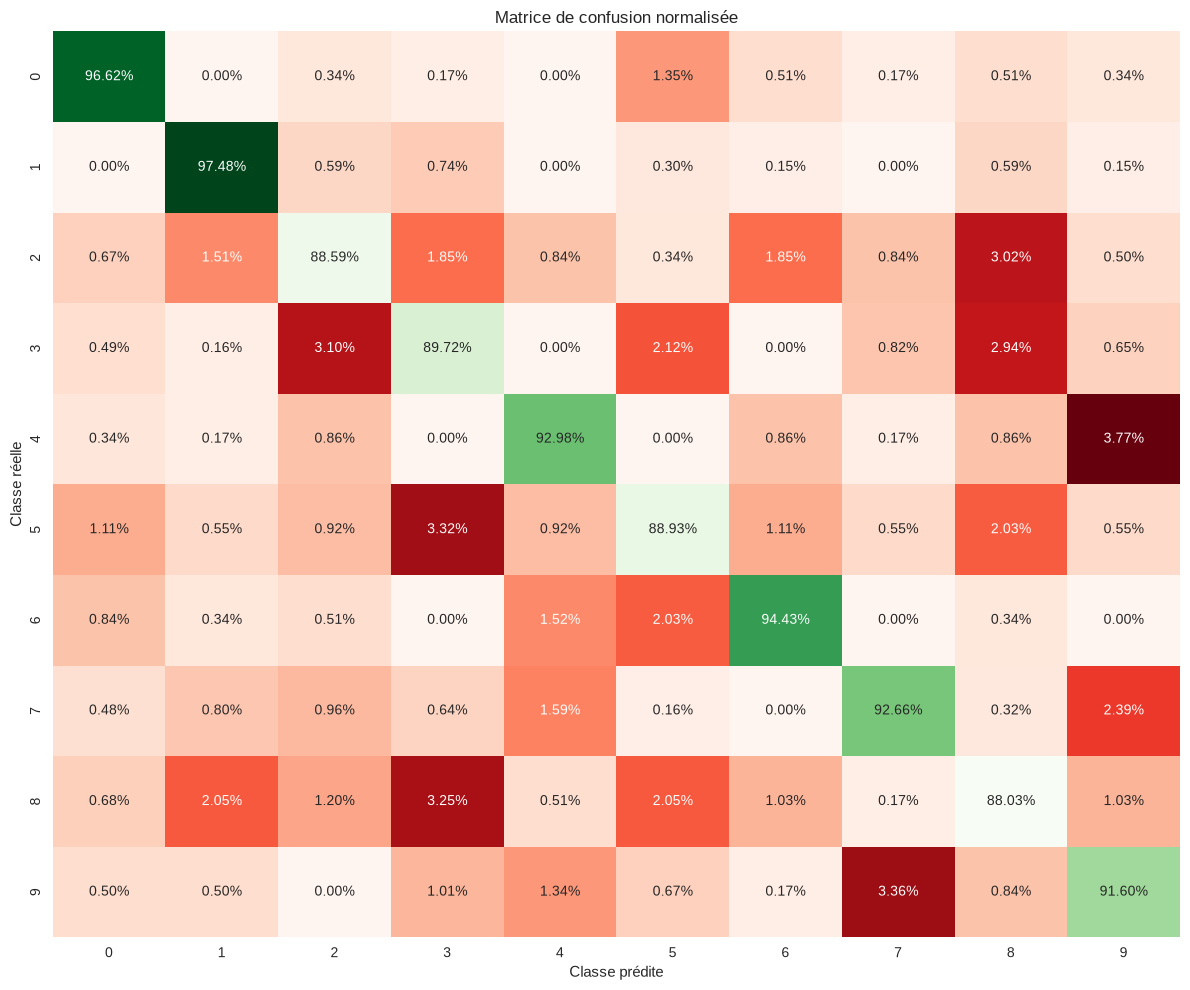

In [89]:
plt.figure(figsize=(12, 10))

mask_diag = np.eye(
    cm_normalized.shape[0],
    dtype=bool,
)

sns.heatmap(
    cm_normalized,
    mask=mask_diag,
    annot=True,
    fmt=".2%",
    cmap="Reds",
    cbar=False,
)

sns.heatmap(
    cm_normalized,
    mask=~mask_diag,
    annot=True,
    fmt=".2%",
    cmap="Greens",
    cbar=False,
)

plt.title("Matrice de confusion normalisée")

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_confusion_matrix_normalized.png",
    bbox_inches="tight",
)

plt.show()

# Analyse de la matrice de confusion normalisée

La matrice de confusion normalisée représente les proportions de classification plutôt que les effectifs bruts.

Chaque ligne totalise 100 % et décrit la manière dont une classe réelle est répartie entre les différentes prédictions du modèle.

Cette représentation permet de comparer directement les performances obtenues sur chaque chiffre.

## Classes les mieux reconnues

Les meilleures performances sont observées pour :

- Classe 1 : 97,48 %
- Classe 0 : 96,62 %
- Classe 6 : 94,43 %

Ces résultats indiquent que ces chiffres possèdent des caractéristiques visuelles suffisamment distinctives pour être correctement identifiées par une régression logistique.

La quasi-totalité des exemples appartenant à ces classes est correctement classifiée.

## Classes les plus difficiles

Les performances les plus faibles sont observées pour :

- Classe 8 : 88,03 %
- Classe 2 : 88,59 %
- Classe 5 : 88,93 %
- Classe 3 : 89,72 %

Ces classes présentent une plus grande variabilité graphique et génèrent davantage de confusions.

Cette observation est cohérente avec les analyses réalisées lors de l'exploration des données.

## Principales confusions relatives

La normalisation met en évidence plusieurs couples de classes particulièrement problématiques :

### Classe 4 → Classe 9


3,77 %

Il s'agit de la confusion relative la plus importante observée dans la matrice.

Certaines écritures manuscrites du chiffre 4 présentent en effet une structure proche du chiffre 9.

### Classe 9 → Classe 7


3,36 %

Cette confusion est également fréquente et semble liée à certaines variantes manuscrites incomplètes ou atypiques.

### Classe 5 → Classe 3

3,32 %

Certaines écritures du chiffre 5 peuvent présenter des formes partiellement ouvertes rappelant un 3.

### Classe 8 → Classe 3

3,25 %

Le chiffre 8 apparaît comme l'une des classes les plus difficiles à distinguer.

### Classe 3 → Classe 2

3,10 %

Les chiffres 2 et 3 possèdent certains motifs visuels similaires susceptibles d'être confondus par une approche linéaire.

### Classe 2 → Classe 8

3,02 %

Cette confusion confirme la difficulté déjà observée sur la classe 8.

## Interprétation

La matrice normalisée montre que les erreurs ne sont pas réparties uniformément.

Certaines paires de classes concentrent une part importante des erreurs et correspondent généralement à des chiffres dont les formes manuscrites peuvent être proches.

Ces résultats suggèrent que la principale limitation de la régression logistique ne réside pas dans le nombre d'exemples disponibles mais dans sa capacité à modéliser les structures spatiales complexes présentes dans les images.

Cette limitation constitue précisément la motivation du recours futur aux réseaux de neurones et en particulier aux architectures convolutives.

La classe 8 apparaît simultanément comme : 
*   la classe la moins bien reconnue ; 
*   l'une des classes les plus souvent impliquées dans les confusions. 

Ce résultat est cohérent avec les observations réalisées durant l'exploration des données où le chiffre 8 présentait déjà une forte variabilité graphique.

# Analyse quantitative automatique 

In [67]:
class_accuracy = np.diag(cm_normalized)

class_results = pd.DataFrame(
    {
        "Classe": range(10),
        "Accuracy": class_accuracy,
    }
)

class_results

,Classe,Accuracy
0,0,0.966216
1,1,0.974777
2,2,0.885906
3,3,0.897227
4,4,0.929795
5,5,0.889299
6,6,0.944257
7,7,0.926635
8,8,0.880342
9,9,0.915966


In [68]:
class_results.to_csv(
    "../reports/experiments/baseline_class_accuracy.csv",
    index=False,
)

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

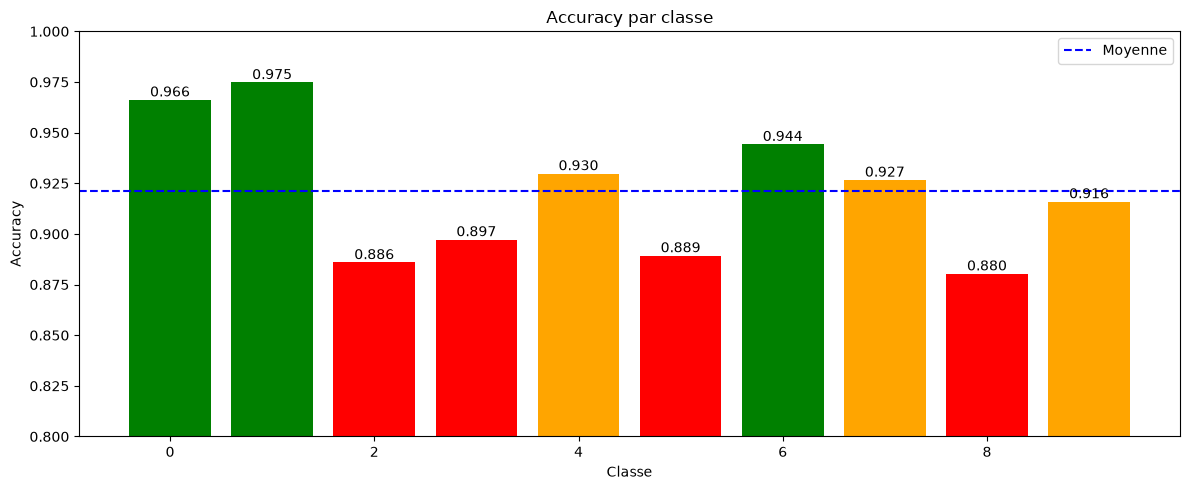

In [75]:
colors = []

for acc in class_results["Accuracy"]:
    if acc >= 0.94:
        colors.append("green")
    elif acc <= 0.90:
        colors.append("red")
    else:
        colors.append("orange")
        plt.figure(figsize=(12, 5))

bars = plt.bar(
    class_results["Classe"],
    class_results["Accuracy"],
    color=colors,
)

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom",
    )

plt.axhline(
    class_results["Accuracy"].mean(),
    color="blue",
    linestyle="--",
    label="Moyenne",
)

plt.ylim(0.80, 1.0)

plt.title("Accuracy par classe")

plt.xlabel("Classe")
plt.ylabel("Accuracy")

plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_accuracy_per_class.png",
    bbox_inches="tight",
)

plt.show()

# Analyse des performances par classe

L'accuracy calculée pour chaque classe permet d'évaluer plus précisément les différences de comportement du modèle selon le chiffre considéré.

## Performance moyenne

L'accuracy globale de la baseline est de :

92,20 %

Cependant, les performances ne sont pas homogènes selon les classes.

### Classes les mieux reconnues
Les meilleures performances sont obtenues pour :
| Classe	| Accuracy |
|-----------|----------|
|1|97,48 %|
|0|96,62 %|
|6|94,43 %|
|4|92,98 %|
|7|92,66 %|

Ces chiffres présentent des formes relativement caractéristiques et génèrent peu d'ambiguïtés pour le modèle.

La classe 1 est particulièrement facile à identifier avec près de 98 % de classifications correctes.

### Classes les plus difficiles 

Les performances les plus faibles sont observées pour : 

| Classe	| Accuracy |
|-----------|----------|
|8|88,03 %|
|2|88,59 %|
|5|88,93 %|
|3|89,72 %|

Ces classes présentent une plus forte variabilité graphique et sont impliquées dans plusieurs confusions observées précédemment dans les matrices de confusion.

La classe 8 apparaît comme la plus difficile à reconnaître.

### Écart entre les classes

L'écart entre la meilleure et la moins bonne classe est de :

97,48 % - 88,03 % = 9,44 points

Cette différence montre que les performances globales du modèle masquent des comportements différents selon les chiffres étudiés.

### Cohérence avec les analyses précédentes

Ces résultats confirment plusieurs observations déjà formulées :

les chiffres les plus simples à distinguer (0, 1, 6) obtiennent les meilleures performances ;
les chiffres présentant davantage de variabilité (2, 3, 5, 8) sont plus difficiles à classifier ;
les confusions les plus fréquentes observées dans les matrices concernent principalement les classes les moins performantes.

On retrouve notamment la classe 8 parmi les plus problématiques, ce qui confirme les observations réalisées durant l'analyse exploratoire du dataset.


# Analyse croisée

Il est intéressant de constater que les classes les moins performantes correspondent également à celles qui participent le plus grand nombre de confusions dans les matrices précédentes. 

Par exemple : 
*   le chiffre 8 est la classe la moins bien reconnue et apparaît dans plusieurs confusions importantes ; 
*   les chiffres 2 et 3 présentent également une accuracy plus faible et sont régulièrement confondus entre eux ; 
*   le chiffre 5 est souvent confondu avec le chiffre 3. 

Cette cohérence entre les différents indicateurs renforce la crédibilité des résultats obtenus.

---

# Synthèse globale des erreurs de classification

Les différentes analyses réalisées mettent en évidence plusieurs tendances cohérentes.

## Performances générales

La régression logistique atteint une accuracy globale de :


92,20 %

Les résultats observés durant la validation croisée, la validation indépendante et le bootstrap sont très proches, suggérant une bonne capacité de généralisation du modèle.

## Classes les mieux reconnues
Les meilleures performances sont observées pour :

*   Classe 1 : 97,48 %
*   Classe 0 : 96,62 %
*   Classe 6 : 94,43 %

Ces chiffres présentent des motifs visuels relativement simples et peu ambigus.

## Classes les plus difficiles

Les classes générant le plus d'erreurs sont :

*   Classe 8 : 88,03 %
*   Classe 2 : 88,59 %
*   Classe 5 : 88,93 %
*   Classe 3 : 89,72 %

Ces résultats sont cohérents avec les observations réalisées lors de l'exploration du dataset où ces chiffres présentaient une plus forte variabilité intra-classe.

## Principales confusions

Les erreurs se concentrent principalement sur quelques couples de classes :

4 → 9
9 → 7
5 → 3
3 → 2
8 → 3
2 → 8

Ces confusions concernent essentiellement des chiffres dont certaines variantes manuscrites possèdent des caractéristiques visuelles proches.

## Limites du modèle

La régression logistique traite les pixels comme des caractéristiques indépendantes.

Elle ne modélise pas directement :

les formes globales ;
les contours ;
les motifs locaux ;
les relations spatiales entre pixels.

Cette limitation explique vraisemblablement les difficultés observées sur certaines classes complexes.

# Conclusion BASELINE-02 

L'analyse de la matrice de confusion confirme les bonnes performances générales de la baseline tout en mettant en évidence plusieurs limites du modèle. 

Les erreurs observées ne sont pas réparties uniformément et se concentrent principalement sur quelques paires de chiffres visuellement proches. 

La classe 8 apparaît comme la plus difficile à classifier tandis que les classes 0, 1 et 6 sont reconnues avec une grande fiabilité. 

Ces résultats fournissent une compréhension détaillée du comportement du modèle et permettent d'identifier précisément les difficultés qui devront être surmontées par les futurs modèles de Deep Learning. 

L'étape suivante consistera à étudier directement les images mal classées afin de comprendre les causes visuelles des erreurs observées.

# Analyse des erreurs

Les matrices de confusion ont mis en évidence plusieurs classes difficiles à reconnaître ainsi que différentes confusions récurrentes.

L'objectif de cette section est d'étudier directement les exemples mal classés afin de comprendre les causes visuelles des erreurs réalisées par la régression logistique.

Cette analyse doit permettre :

- d'identifier les chiffres les plus ambigus ;
- de relier les erreurs observées aux confusions mises en évidence précédemment ;
- de comprendre les limites de la régression logistique ;
- de préparer l'analyse comparative avec les futurs modèles MLP et CNN.

# Identifier les erreurs

In [76]:
misclassified_idx = np.where(y_val != y_val_pred)[0]

print(f"Nombre d'erreurs : {len(misclassified_idx)}")

print(f"Taux d'erreur : {len(misclassified_idx) / len(y_val):.2%}")

Nombre d'erreurs : 468
Taux d'erreur : 7.80%


# Visualiser quelques erreurs

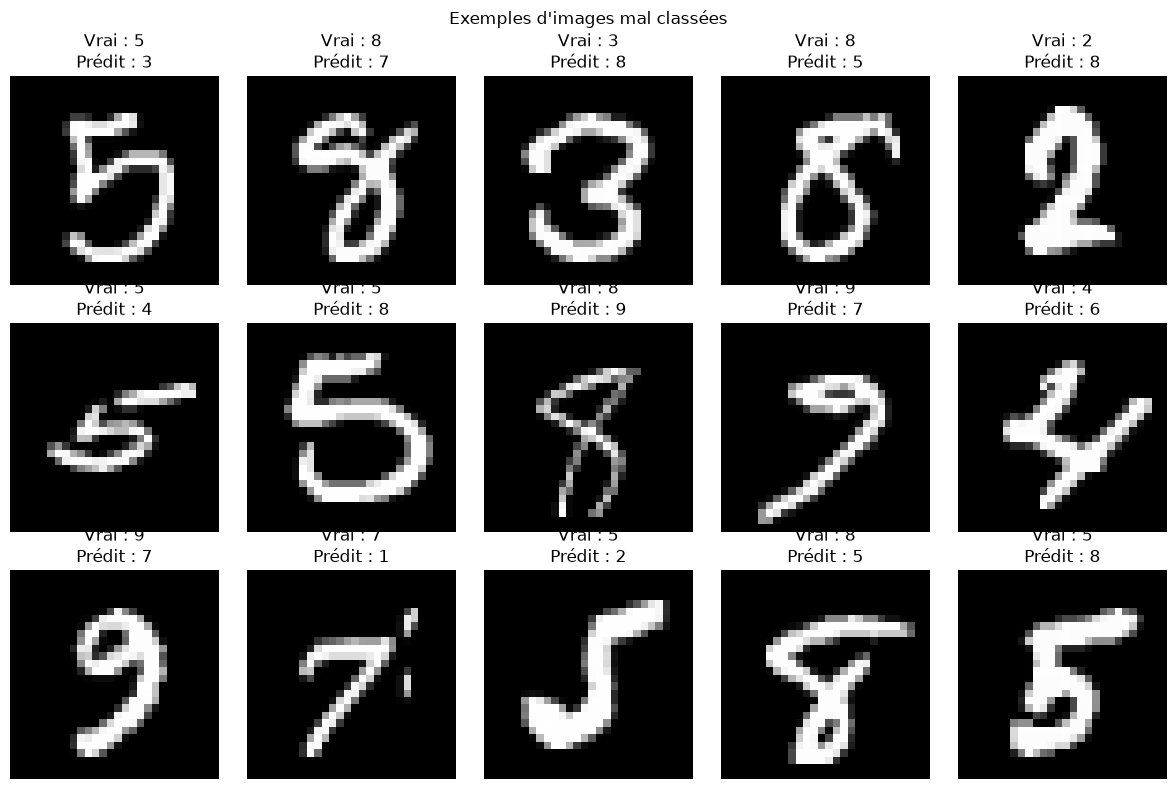

In [77]:
fig, axes = plt.subplots(3, 5, figsize=(12, 8))

for ax, idx in zip(axes.ravel(), misclassified_idx[:15]):
    ax.imshow(
        x_val[idx],
        cmap="gray",
    )

    ax.set_title(f"Vrai : {y_val[idx]}\nPrédit : {y_val_pred[idx]}")

    ax.axis("off")

plt.suptitle("Exemples d'images mal classées")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_misclassified_examples.png",
    bbox_inches="tight",
)

plt.show()

# Visualiser les probabilités

In [78]:
y_val_proba = baseline_model.predict_proba(x_val_flat)

In [79]:
error_confidences = y_val_proba[misclassified_idx].max(axis=1)

print(f"Confiance moyenne des erreurs : {error_confidences.mean():.4f}")

Confiance moyenne des erreurs : 0.6764


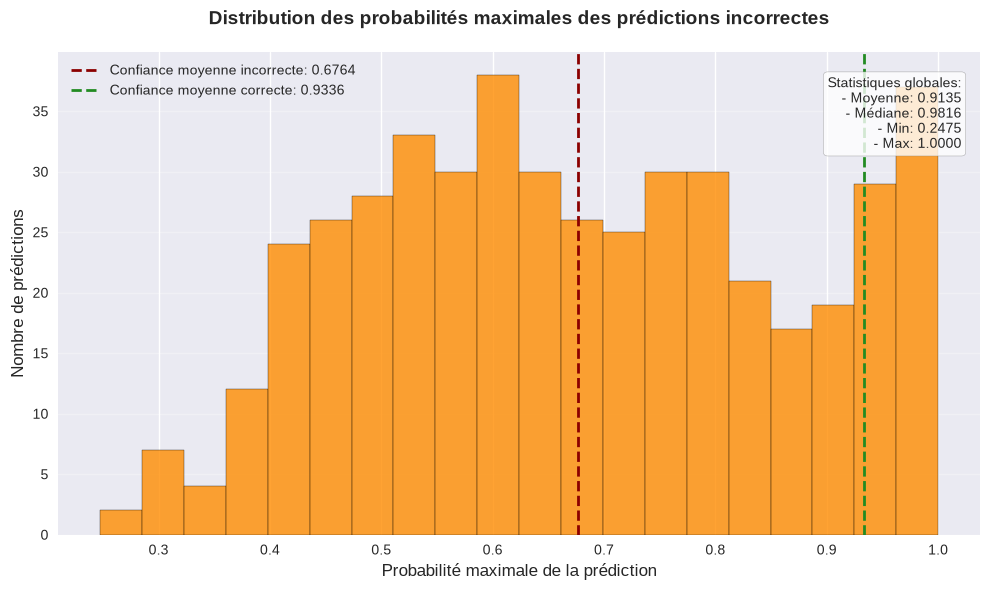

ANALYSE DES PROBABILITÉS MAXIMALES DES PRÉDICTIONS
Confiance moyenne des prédictions correctes : 0.9336
Confiance moyenne des prédictions incorrectes : 0.6764
Confiance moyenne globale : 0.9135
Confiance médiane globale : 0.9816
Confiance minimale globale : 0.2475
Confiance maximale globale : 1.0000


In [87]:
import matplotlib.pyplot as plt
import numpy as np

# Configuration de la figure
plt.figure(figsize=(10, 6))
plt.style.use("seaborn-v0_8")  # Style plus moderne

# Création de l'histogramme
n, bins, patches = plt.hist(
    error_confidences,
    bins=20,
    color="#FF8C00",  # Orange plus doux
    edgecolor="black",
    alpha=0.8,
    density=False,  # Garder les fréquences absolues
)

# Ajout d'une ligne verticale pour la confiance moyenne des prédictions incorrectes
mean_incorrect_conf = y_val_proba[misclassified_idx].max(axis=1).mean()
plt.axvline(
    mean_incorrect_conf,
    color="#8B0000",  # Rouge foncé
    linestyle="--",
    linewidth=2,
    label=f"Confiance moyenne incorrecte: {mean_incorrect_conf:.4f}",
)

# Ajout de la confiance moyenne des prédictions correctes
mean_correct_conf = (
    y_val_proba[~np.isin(range(len(y_val)), misclassified_idx)].max(axis=1).mean()
)
plt.axvline(
    mean_correct_conf,
    color="#228B22",  # Vert forêt
    linestyle="--",
    linewidth=2,
    label=f"Confiance moyenne correcte: {mean_correct_conf:.4f}",
)

# Titre et labels améliorés
plt.title(
    "Distribution des probabilités maximales des prédictions incorrectes",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Probabilité maximale de la prédiction", fontsize=12)
plt.ylabel("Nombre de prédictions", fontsize=12)

# Légende et grille
plt.legend(fontsize=10, framealpha=1, shadow=True)
plt.grid(axis="y", alpha=0.3)
plt.gca().set_axisbelow(True)  # Grille en arrière-plan

# Annotations pour les statistiques clés
stats_text = (
    f"Statistiques globales:\n"
    f"- Moyenne: {y_val_proba.max(axis=1).mean():.4f}\n"
    f"- Médiane: {np.median(y_val_proba.max(axis=1)):.4f}\n"
    f"- Min: {y_val_proba.max(axis=1).min():.4f}\n"
    f"- Max: {y_val_proba.max(axis=1).max():.4f}"
)
plt.gca().text(
    0.98,
    0.95,
    stats_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="gray"),
)

# Mise en page et sauvegarde
plt.tight_layout()
plt.savefig(
    "../reports/figures/baseline_error_confidence.png",
    bbox_inches="tight",
    dpi=300,  # Meilleure résolution
)

plt.show()

# Affichage des statistiques dans la console
print("=" * 50)
print("ANALYSE DES PROBABILITÉS MAXIMALES DES PRÉDICTIONS")
print("=" * 50)
print(f"Confiance moyenne des prédictions correctes : {mean_correct_conf:.4f}")
print(f"Confiance moyenne des prédictions incorrectes : {mean_incorrect_conf:.4f}")
print(f"Confiance moyenne globale : {y_val_proba.max(axis=1).mean():.4f}")
print(f"Confiance médiane globale : {np.median(y_val_proba.max(axis=1)):.4f}")
print(f"Confiance minimale globale : {y_val_proba.max(axis=1).min():.4f}")
print(f"Confiance maximale globale : {y_val_proba.max(axis=1).max():.4f}")
print("=" * 50)

In [84]:
most_confident_errors = misclassified_idx[np.argsort(error_confidences)[::-1]]

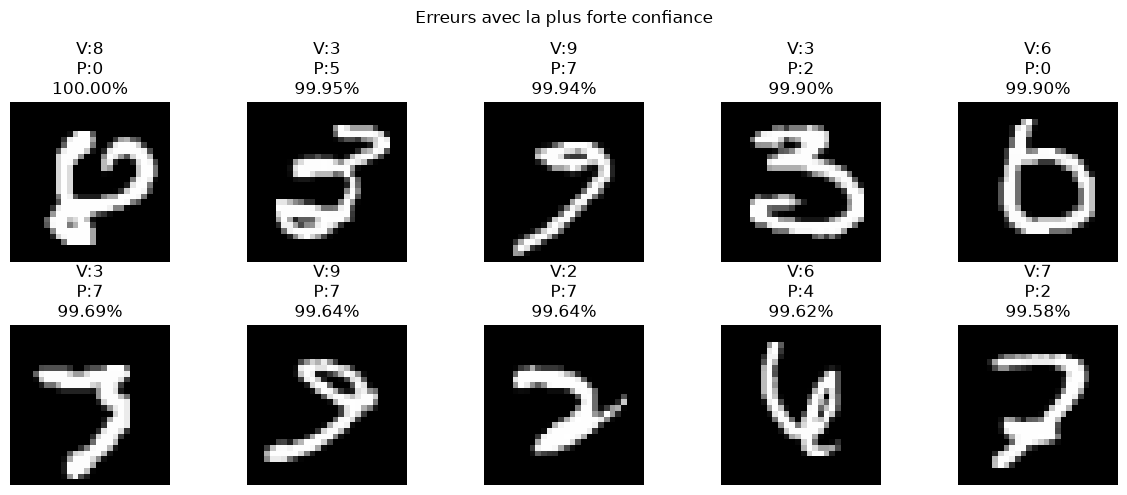

In [82]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, idx in zip(axes.ravel(), most_confident_errors[:10]):
    ax.imshow(
        x_val[idx],
        cmap="gray",
    )

    confidence = y_val_proba[idx].max()

    ax.set_title((f"V:{y_val[idx]}\nP:{y_val_pred[idx]}\n{confidence:.2%}"))

    ax.axis("off")

plt.suptitle("Erreurs avec la plus forte confiance")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_confident_errors.png",
    bbox_inches="tight",
)

plt.show()

In [91]:
# Afficher les erreurs aléatoires et les plus confiantes
print("Erreurs aléatoires :")
for idx in random.sample(list(misclassified_idx), 5):
    print(f"Index : {idx}, Vrai : {y_val[idx]}, Prédit : {y_val_pred[idx]}")

print("\nErreurs les plus confiantes :")
for idx in most_confident_errors[:5]:
    confidence = y_val_proba[idx].max()
    print(
        f"Index : {idx}, Vrai : {y_val[idx]}, Prédit : {y_val_pred[idx]}, "
        f"Confiance : {confidence:.2%}"
    )

Erreurs aléatoires :
Index : 4509, Vrai : 7, Prédit : 0
Index : 4936, Vrai : 2, Prédit : 0
Index : 5856, Vrai : 8, Prédit : 2
Index : 3711, Vrai : 3, Prédit : 1
Index : 544, Vrai : 2, Prédit : 9

Erreurs les plus confiantes :
Index : 726, Vrai : 8, Prédit : 0, Confiance : 100.00%
Index : 5521, Vrai : 3, Prédit : 5, Confiance : 99.95%
Index : 140, Vrai : 9, Prédit : 7, Confiance : 99.94%
Index : 2036, Vrai : 3, Prédit : 2, Confiance : 99.90%
Index : 5301, Vrai : 6, Prédit : 0, Confiance : 99.90%
